#**Details:**
**Name:** Siddhesh Abasaheb Mane

**PRN:** 202401040187

**Batch:** A2

**Roll No.:** 46

#**Title**
Performance Evaluation of Regression Models and Gradient Descent using
application of California House Price Prediction


#**1. Problem Statement**
House value estimation is a regression problem because the target is continuous. The objective is to predict median house value from housing and geographic attributes, compare Simple Linear Regression, Multiple Linear Regression and Polynomial Regression, and implement Batch Gradient Descent for Linear Regression.

#**2. Dataset**
The California Housing dataset contains 20,640 census block-group observations and eight numerical predictors.

| Feature | Description |
|---|---|
| MedInc | Median income |
| HouseAge | Median house age |
| AveRooms | Average rooms per household |
| AveBedrms | Average bedrooms per household |
| Population | Block-group population |
| AveOccup | Average household occupancy |
| Latitude | Latitude |
| Longitude | Longitude |
| MedHouseVal | Target: median house value, units of $100,000

.

#**3. Import Libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries imported.")

Libraries imported.


#**4. Load Dataset**

In [2]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()
print("Shape:", df.shape)
display(df.head())

Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


#**5. Inspect Data**

In [4]:
df.info()
print("\nMissing values:")
display(df.isnull().sum())
print("\nDescriptive statistics:")
display(df.describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Missing values:


,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


#**6. Define X and y; Split Data**

In [6]:
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (16512, 8) Test: (4128, 8)


#**7. Evaluation Function**

In [7]:
def evaluate_regression(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred)
    }

results = []

#**8. Model 1 — Simple Linear Regression (MedInc only)**

In [8]:
simple_model = LinearRegression()
simple_model.fit(X_train[["MedInc"]], y_train)
simple_pred = simple_model.predict(X_test[["MedInc"]])
simple_metrics = evaluate_regression(y_test, simple_pred)
results.append({"Model": "Simple Linear Regression", **simple_metrics})
print("Intercept:", simple_model.intercept_)
print("MedInc coefficient:", simple_model.coef_[0])
print(simple_metrics)

Intercept: 0.4445972916907879
MedInc coefficient: 0.4193384939381271
{'MAE': 0.629908653009376, 'MSE': 0.7091157771765549, 'RMSE': np.float64(0.8420901241414455), 'R2': 0.45885918903846656}


The simple model uses only median income. Its equation is `ŷ = intercept + coefficient × MedInc`.

#**9. Model 2 — Multiple Linear Regression**

In [9]:
multiple_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])
multiple_model.fit(X_train, y_train)
multiple_pred = multiple_model.predict(X_test)
multiple_metrics = evaluate_regression(y_test, multiple_pred)
results.append({"Model": "Multiple Linear Regression", **multiple_metrics})
print(multiple_metrics)

{'MAE': 0.5332001304956565, 'MSE': 0.555891598695244, 'RMSE': np.float64(0.7455813830127761), 'R2': 0.5757877060324511}


The multiple model uses all eight predictors. The scaler is fitted on training data inside the pipeline and then applied consistently to test data.

#**10. Model 3 — Polynomial Regression (degree 2)**

In [10]:
polynomial_model = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("regressor", LinearRegression())
])
polynomial_model.fit(X_train, y_train)
polynomial_pred = polynomial_model.predict(X_test)
polynomial_metrics = evaluate_regression(y_test, polynomial_pred)
results.append({"Model": "Polynomial Regression (degree 2)", **polynomial_metrics})
print("Polynomial feature count:",
      polynomial_model.named_steps["poly"].n_output_features_)
print(polynomial_metrics)

Polynomial feature count: 44
{'MAE': 0.46700093346965726, 'MSE': 0.46430152383011997, 'RMSE': np.float64(0.6813967448044641), 'R2': 0.6456819729261921}


Degree-2 polynomial features include squared terms and pairwise interactions.

#**11. Compare Models**

,MAE,MSE,RMSE,R2
Model,,,,
Polynomial Regression (degree 2),0.467001,0.464302,0.681397,0.645682
Multiple Linear Regression,0.533200,0.555892,0.745581,0.575788
Simple Linear Regression,0.629909,0.709116,0.842090,0.458859


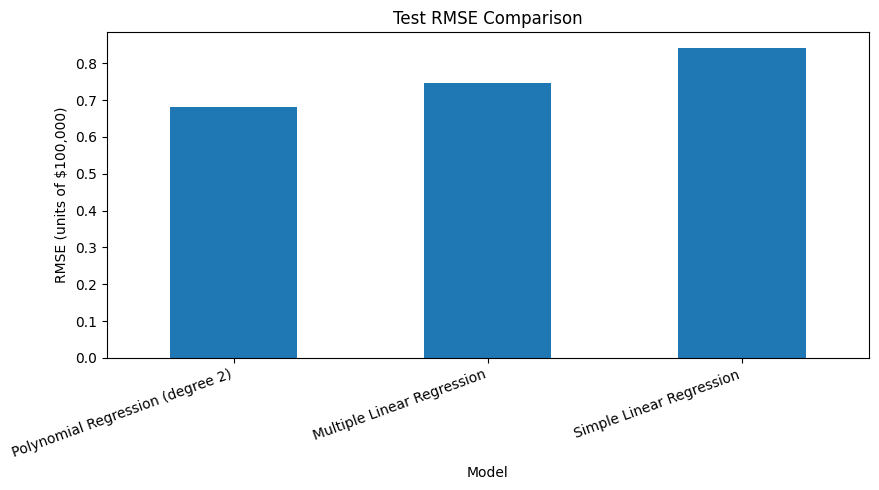

In [11]:
results_df = pd.DataFrame(results).set_index("Model")
display(results_df.sort_values("RMSE"))

results_df["RMSE"].sort_values().plot(kind="bar", figsize=(9,5), title="Test RMSE Comparison")
plt.ylabel("RMSE (units of $100,000)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Metric interpretation
- MAE: average absolute error; lower is better.
- MSE: average squared error; lower is better and large errors receive stronger penalty.
- RMSE: square root of MSE, in target units; lower is better.
- R²: 1 is perfect; 0 means performance equal to predicting the test-set target mean under the standard definition; negative means worse than that baseline.

#**12. Batch Gradient Descent — Prepare Data**

In [12]:
# Fit scalers only on training data
X_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_s = X_scaler.fit_transform(X_train)
X_test_s = X_scaler.transform(X_test)
y_train_s = y_scaler.fit_transform(y_train.to_numpy().reshape(-1,1)).ravel()

# Add intercept column
X_train_gd = np.c_[np.ones((len(X_train_s),1)), X_train_s]
X_test_gd = np.c_[np.ones((len(X_test_s),1)), X_test_s]
print("GD training matrix:", X_train_gd.shape)

GD training matrix: (16512, 9)


#**13. Implement Batch Gradient Descent**

In [13]:
def batch_gradient_descent(X, y, learning_rate=0.03, iterations=2000):
    m, n = X.shape
    theta = np.zeros(n)
    cost_history = []

    for _ in range(iterations):
        predictions = X @ theta
        errors = predictions - y
        cost = np.sum(errors**2) / (2*m)
        gradients = (X.T @ errors) / m
        theta = theta - learning_rate * gradients
        cost_history.append(cost)

    return theta, cost_history

alpha = 0.03
iterations = 2000
theta_gd, cost_history = batch_gradient_descent(
    X_train_gd, y_train_s, learning_rate=alpha, iterations=iterations
)
print("Parameters:", theta_gd)
print("Initial cost:", cost_history[0])
print("Final recorded cost:", cost_history[-1])

Parameters: [ 4.18521645e-15  7.43956141e-01  1.07860103e-01 -2.62076632e-01
  2.98695166e-01 -1.38860508e-03 -3.56129684e-02 -7.57568421e-01
 -7.34648688e-01]
Initial cost: 0.5
Final recorded cost: 0.19374332889998946


#**14. Plot Gradient Descent Convergence**

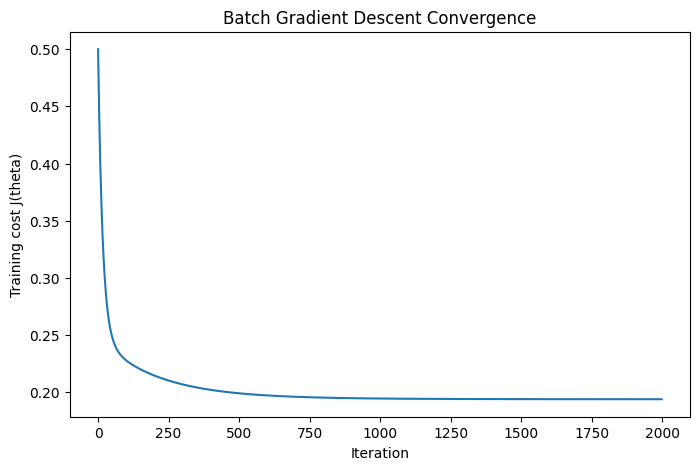

In [14]:
plt.figure(figsize=(8,5))
plt.plot(cost_history)
plt.xlabel("Iteration")
plt.ylabel("Training cost J(theta)")
plt.title("Batch Gradient Descent Convergence")
plt.show()

#**15. Evaluate Gradient Descent**

In [15]:
gd_pred_scaled = X_test_gd @ theta_gd
gd_pred = y_scaler.inverse_transform(gd_pred_scaled.reshape(-1,1)).ravel()
gd_metrics = evaluate_regression(y_test, gd_pred)
results.append({"Model": "Multiple Linear Regression (Batch GD)", **gd_metrics})
print("Gradient Descent test metrics:", gd_metrics)
all_results = pd.DataFrame(results).set_index("Model")
display(all_results.sort_values("RMSE"))

Gradient Descent test metrics: {'MAE': 0.5329688996290839, 'MSE': 0.5562556226758774, 'RMSE': np.float64(0.7458254639497618), 'R2': 0.5755099118577485}


,MAE,MSE,RMSE,R2
Model,,,,
Polynomial Regression (degree 2),0.467001,0.464302,0.681397,0.645682
Multiple Linear Regression,0.533200,0.555892,0.745581,0.575788
Multiple Linear Regression (Batch GD),0.532969,0.556256,0.745825,0.575510
Simple Linear Regression,0.629909,0.709116,0.842090,0.458859


#**16. Compare Gradient Descent with Scikit-learn**

In [18]:
comparison = pd.DataFrame({
    "Method": ["Scikit-learn Multiple Linear Regression", "Batch Gradient Descent"],
    "MAE": [mean_absolute_error(y_test, multiple_pred), mean_absolute_error(y_test, gd_pred)],
    "MSE": [mean_squared_error(y_test, multiple_pred), mean_squared_error(y_test, gd_pred)],
    "RMSE": [np.sqrt(mean_squared_error(y_test, multiple_pred)),
             np.sqrt(mean_squared_error(y_test, gd_pred))],
    "R2": [r2_score(y_test, multiple_pred), r2_score(y_test, gd_pred)]
}).set_index("Method")
display(comparison)

,MAE,MSE,RMSE,R2
Method,,,,
Scikit-learn Multiple Linear Regression,0.533200,0.555892,0.745581,0.575788
Batch Gradient Descent,0.532969,0.556256,0.745825,0.575510


#**17. Actual vs Predicted Plot**

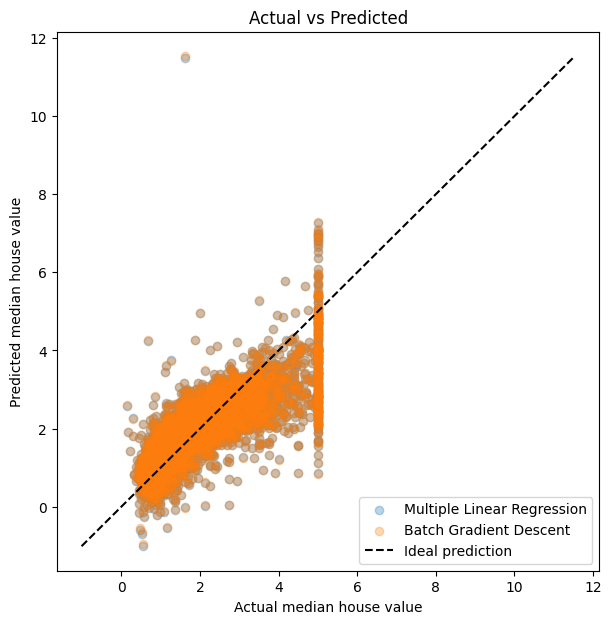

In [16]:
plt.figure(figsize=(7,7))
plt.scatter(y_test, multiple_pred, alpha=0.3, label="Multiple Linear Regression")
plt.scatter(y_test, gd_pred, alpha=0.3, label="Batch Gradient Descent")
lo = min(y_test.min(), multiple_pred.min(), gd_pred.min())
hi = max(y_test.max(), multiple_pred.max(), gd_pred.max())
plt.plot([lo,hi], [lo,hi], "k--", label="Ideal prediction")
plt.xlabel("Actual median house value")
plt.ylabel("Predicted median house value")
plt.title("Actual vs Predicted")
plt.legend()
plt.show()

#**Conclusion**

The experiment successfully implemented and compared Scikit-learn Multiple Linear Regression with Batch Gradient Descent for house price prediction. Both methods produced very similar results.

Scikit-learn Multiple Linear Regression achieved an MAE of 0.533200, MSE of 0.555892, RMSE of 0.745581, and R² score of 0.575788. Batch Gradient Descent achieved an MAE of 0.532969, MSE of 0.556256, RMSE of 0.745825, and R² score of 0.575510.

The results show that Batch Gradient Descent performed almost equally well as Scikit-learn's implementation. It had a slightly lower MAE, while Scikit-learn achieved slightly lower MSE and RMSE and a marginally higher R² score. This demonstrates that Gradient Descent can effectively optimise Linear Regression parameters when the learning rate and number of iterations are appropriately selected.

Overall, this practical helped me understand regression modelling, model evaluation metrics, and the working of Gradient Descent from scratch. It also demonstrated how optimisation techniques can be used to train machine learning models for real-world prediction problems.

#**Github Link**
[click here](https://github.com/siddheshmane18/AIML_SEM5/tree/main/Continuous%20Assessment)

#**Colab Link**
[click here](https://colab.research.google.com/drive/1kKSwNjczi7N7qUYOkmWQxcbWWQT0u3gQ?usp=drive_link)


